# **Task 6 — YOLO**: why does YOLO lose birds in a flock?

This week's seminar was about [YOLO](https://openaccess.thecvf.com/content_cvpr_2016/html/Redmon_You_Only_Look_CVPR_2016_paper.html). It cuts the image into a grid, and each grid cell predicts boxes for the objects whose centre falls inside it, all in one pass of one network. The paper admits one weakness (§2.4): *"Our model struggles with small objects that appear in groups, such as flocks of birds."*

This notebook gives you scenes with scattered objects and with flocks, a **small YOLO built as in the paper**, a **training loop** and a **fixed evaluation**. The task is on the card.

<details>
<summary>Reach out here if you have any problems</summary>
Taras Kutsyk — taras.kutsyk@doctoral.uj.edu.pl
</details>

# Setup

**Step 0.** Runtime → Change runtime type → **T4 GPU**. Everything we need is already installed on Colab.

**Step 1. Data** (about 30 seconds). 128×128 images with three kinds of objects: discs, squares and triangles, in random colours on a noisy background. There are two kinds of scenes:

- **scattered**: 2–6 objects, 14–36 pixels wide, anywhere in the image;
- **flock**: 1–2 tight clusters of 6–14 objects, each 6–11 pixels wide, one shape per cluster.

The **training set** has 6,000 images (half scattered, half flocks). The **test sets** have 400 scattered and 400 flock images. All of them are generated from fixed seeds, so everyone has exactly the same data. `make_scene()` generates new scenes; use it for your Part 1 analysis if you like, but train only on the training set (card).

train (6000, 3, 128, 128), test: 400 scattered, 400 flock (20 s)


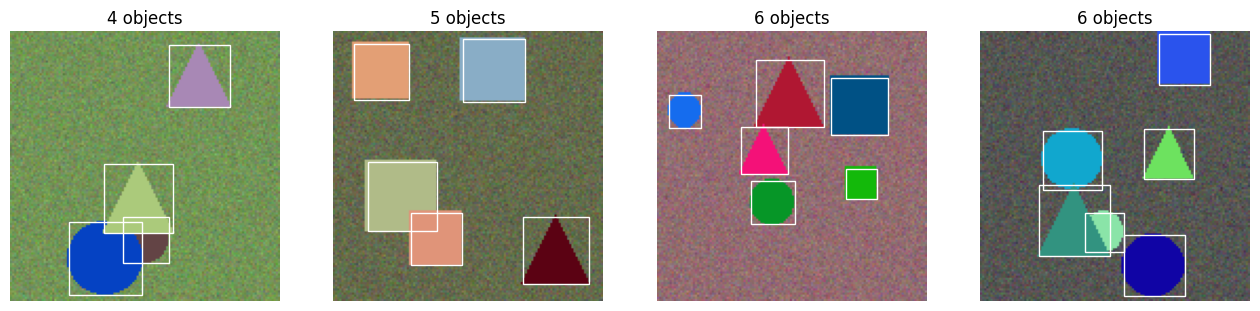

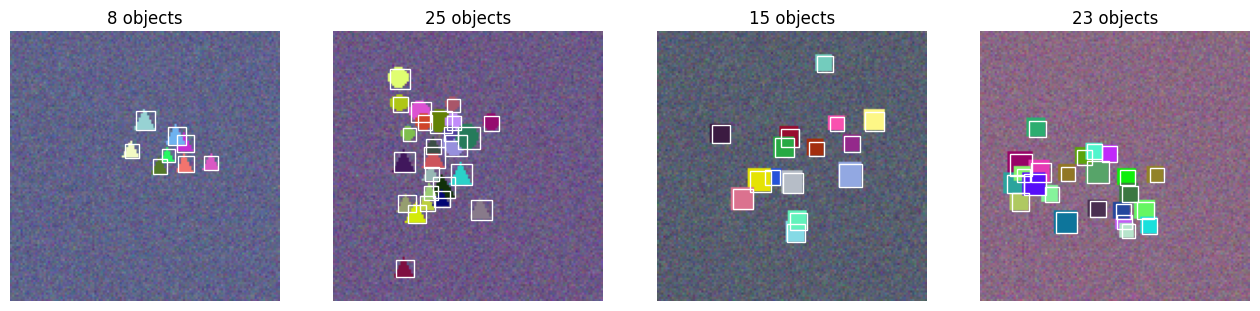

In [1]:
import math, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from torchvision.ops import box_iou, batched_nms

device = "cuda" if torch.cuda.is_available() else "cpu"
assert device == "cuda", "Switch to a GPU runtime: Runtime -> Change runtime type -> T4 GPU"

SIZE, CLASSES = 128, ["disc", "square", "triangle"]

def overlap(box, boxes):
    # IoU of one [x0, y0, x1, y1] box with each row of boxes (n, 4), in numpy (used only to place objects)
    w = (np.minimum(box[2], boxes[:, 2]) - np.maximum(box[0], boxes[:, 0])).clip(0)
    h = (np.minimum(box[3], boxes[:, 3]) - np.maximum(box[1], boxes[:, 1])).clip(0)
    area = lambda b: (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return w * h / (area(np.array(box)) + area(boxes) - w * h)

def make_scene(kind, rng):
    # kind - "scattered" or "flock"; rng - a np.random.Generator (the same seed gives the same scene)
    # returns: image (128, 128, 3) uint8, boxes (n, 4) as [x0, y0, x1, y1] in pixels, labels (n,) indices into CLASSES
    background = rng.uniform(.3, .6, 3) * 255 + rng.normal(0, 12, (SIZE, SIZE, 3))
    image = Image.fromarray(background.clip(0, 255).astype(np.uint8))
    draw = ImageDraw.Draw(image)
    if kind == "scattered":
        objects = [(rng.integers(3), rng.uniform(14, 36), None) for _ in range(rng.integers(2, 7))]
    else:
        objects = []
        for _ in range(rng.integers(1, 3)):
            shape, centre = rng.integers(3), rng.uniform(25, SIZE - 25, 2)
            objects += [(shape, rng.uniform(6, 11), centre) for _ in range(rng.integers(6, 15))]
    boxes, labels = [], []
    for shape, size, centre in objects:
        for _ in range(30):  # objects may touch, but not pile up on each other
            x0, y0 = rng.uniform(0, SIZE - size, 2) if centre is None else (rng.normal(centre, 11) - size / 2).clip(0, SIZE - size)
            box = [x0, y0, x0 + size, y0 + size]
            if not boxes or overlap(box, np.array(boxes)).max() < .2:
                break
        else:
            continue  # no free spot found: skip this object
        colour = tuple(int(c) for c in rng.integers(0, 256, 3))
        if shape == 0: draw.ellipse(box, fill=colour)
        elif shape == 1: draw.rectangle(box, fill=colour)
        else: draw.polygon([(x0 + size / 2, y0), (x0, y0 + size), (x0 + size, y0 + size)], fill=colour)
        boxes.append(box); labels.append(int(shape))
    return np.asarray(image), torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4), torch.tensor(labels, dtype=torch.long)

def make_set(kinds, n, seed):
    # returns: images (n, 3, 128, 128) uint8 on the GPU, and objects: a list of n (boxes, labels) pairs
    rng = np.random.default_rng(seed)
    scenes = [make_scene(kinds[i % len(kinds)], rng) for i in range(n)]
    images = torch.from_numpy(np.stack([s[0] for s in scenes])).permute(0, 3, 1, 2).contiguous().to(device)
    return images, [(s[1], s[2]) for s in scenes]

def show(images, objects, detections=None, min_score=.3, n=4):
    # draws the first n images: true boxes in white, and detections with score >= min_score in red
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4.3))
    for i, ax in enumerate(axes):
        ax.imshow(images[i].permute(1, 2, 0).cpu()); ax.axis("off")
        for x0, y0, x1, y1 in objects[i][0].tolist():
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="white", lw=1))
        title = f"{len(objects[i][0])} objects"
        if detections is not None:
            keep = detections[i]["scores"] >= min_score
            for x0, y0, x1, y1 in detections[i]["boxes"][keep].tolist():
                ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="red", lw=1.5))
            title += f", {int(keep.sum())} detections"
        ax.set_title(title)
    plt.show()

start = time.time()
train_images, train_objects = make_set(["scattered", "flock"], 6000, seed=0)
test_sets = {"scattered": make_set(["scattered"], 400, seed=1), "flock": make_set(["flock"], 400, seed=2)}
print(f"train {tuple(train_images.shape)}, test: " + ", ".join(f"{len(v[0])} {k}" for k, v in test_sets.items()) + f" ({time.time() - start:.0f} s)")
show(*test_sets["scattered"])
show(*test_sets["flock"])

**Step 2. The detector**: YOLO as in the paper (§2), at our scale.

```
image 128x128 -> 8 conv layers, 4 of them halve the size -> an 8x8 grid of cells
each cell: 2 boxes x (x, y, w, h, confidence) + 3 class probabilities = 13 numbers
  x, y = the box centre inside its cell (0..1)      w, h = box size as a fraction of the image (0..1)
```

Differences from the paper, all for speed at our small scale: 8 conv layers instead of 24 plus 2 fully connected ones, batch norm, an 8×8 grid instead of 7×7, and a sigmoid on the box numbers so they stay in 0..1. The grid, the 2 boxes and one set of class probabilities per cell are exactly as in the paper.

In [2]:
S, B, C = 8, 2, len(CLASSES)   # grid size, boxes per cell, classes (paper: 7, 2, 20)

def conv(c_in, c_out, stride):
    return [nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm2d(c_out), nn.LeakyReLU(.1)]

class TinyYOLO(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(*conv(3, 32, 1), *conv(32, 64, 2), *conv(64, 64, 1), *conv(64, 128, 2), *conv(128, 128, 1),
                                 *conv(128, 256, 2), *conv(256, 256, 1), *conv(256, 256, 2), nn.Conv2d(256, B * 5 + C, 1))

    def forward(self, images):
        # images - (batch, 3, 128, 128) uint8
        # returns: (batch, S, S, B * 5 + C) raw outputs, the 13 numbers of each cell
        return self.net(images.float() / 255 - .5).permute(0, 2, 3, 1)

def split(out):
    # raw outputs -> boxes (batch, S, S, B, 4) as (x, y, w, h), confidences (batch, S, S, B), class probabilities (batch, S, S, C)
    boxes = out[..., :B * 5].reshape(*out.shape[:3], B, 5).sigmoid()
    return boxes[..., :4], boxes[..., 4], out[..., B * 5:].softmax(-1)

row, col = torch.meshgrid(torch.arange(S, device=device), torch.arange(S, device=device), indexing="ij")

def to_corners(xywh, row, col):
    # (x, y inside cell (row, col), w, h) -> (x0, y0, x1, y1) in pixels
    cx, cy = (xywh[..., 0] + col) / S, (xywh[..., 1] + row) / S
    w, h = xywh[..., 2], xywh[..., 3]
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1) * SIZE

print(f"TinyYOLO: {sum(p.numel() for p in TinyYOLO().parameters()) / 1e6:.1f}M parameters")

TinyYOLO: 1.8M parameters


**Step 3. Training targets and the loss** (the paper's §2.2, the five-term loss on the lecture slide).

- `make_targets` turns each image's true boxes into what every cell should output. The cell that holds an object's centre is responsible for it, and each cell holds at most one object, as in the paper.
- `yolo_loss` is the paper's loss. In each cell with an object, the box with the higher IoU is "responsible": it learns the box (terms 1–2, weight 5, with √w and √h) and to set its confidence to its IoU (term 3). Every other box learns confidence 0 (term 4, weight 0.5). The class probabilities are learned only in cells with an object (term 5).

In [3]:
def make_targets(objects):
    # objects - a list of (boxes, labels), one pair per image
    # returns: (N, S, S, 5 + C) on the GPU; per cell: x, y (inside the cell), w, h, has_object, one-hot class
    targets = torch.zeros(len(objects), S, S, 5 + C)
    for n, (boxes, labels) in enumerate(objects):
        for (x0, y0, x1, y1), label in zip(boxes.tolist(), labels.tolist()):
            cx, cy = (x0 + x1) / 2 / SIZE * S, (y0 + y1) / 2 / SIZE * S
            i, j = min(int(cy), S - 1), min(int(cx), S - 1)
            if targets[n, i, j, 4]:
                continue  # the cell already holds an object
            targets[n, i, j, :5] = torch.tensor([cx - j, cy - i, (x1 - x0) / SIZE, (y1 - y0) / SIZE, 1.])
            targets[n, i, j, 5 + label] = 1
    return targets.to(device)

def paired_iou(a, b):
    # IoU of matching pairs of (x0, y0, x1, y1) boxes, broadcasting over the leading dimensions
    top_left, bottom_right = torch.max(a[..., :2], b[..., :2]), torch.min(a[..., 2:], b[..., 2:])
    overlap = (bottom_right - top_left).clamp(min=0).prod(-1)
    area = lambda x: (x[..., 2] - x[..., 0]) * (x[..., 3] - x[..., 1])
    return overlap / (area(a) + area(b) - overlap + 1e-9)

def yolo_loss(out, targets, l_coord=5., l_noobj=.5):
    # out - raw outputs (N, S, S, B * 5 + C); targets - from make_targets
    # returns: the paper's loss, summed over cells and boxes, averaged over images
    xywh, confidence, probs = split(out.float())
    has_object = targets[..., 4] > 0                                    # (N, S, S)
    true_xywh = targets[..., None, :4]                                  # (N, S, S, 1, 4)
    iou = paired_iou(to_corners(xywh, row[..., None], col[..., None]), to_corners(true_xywh, row[..., None], col[..., None]))
    responsible = F.one_hot(iou.argmax(-1), B).bool() & has_object[..., None]   # (N, S, S, B)
    box_error = ((xywh[..., :2] - true_xywh[..., :2]) ** 2).sum(-1) + ((xywh[..., 2:].sqrt() - true_xywh[..., 2:].sqrt()) ** 2).sum(-1)
    loss = (l_coord * box_error[responsible].sum()                         # terms 1-2: centre, and size via sqrt
            + ((confidence - iou.detach()) ** 2)[responsible].sum()        # term 3: confidence -> IoU
            + l_noobj * (confidence ** 2)[~responsible].sum()              # term 4: all other boxes -> 0
            + ((probs - targets[..., 5:]) ** 2).sum(-1)[has_object].sum()) # term 5: class probabilities
    return loss / len(out)

train_targets = make_targets(train_objects)
print("training targets:", tuple(train_targets.shape))

training targets: (6000, 8, 8, 8)


**Step 4. Detection and the fixed evaluation** (DON'T modify `evaluate`).

- `detect(model, images)` scores every box for every class as *confidence × class probability* (the paper's §2.3), drops scores below 0.01, then runs **NMS** per class: keep the highest-scoring box and delete the boxes of the same class that overlap it by more than `nms_iou`. It returns one dict per image with `"boxes"` (pixels), `"scores"` and `"labels"`.
- `evaluate(model)` runs `detect` on both test sets and returns their **mAP** in %, at IoU 0.5 as in the paper's tables: per class, the area under the precision–recall curve, averaged over the 3 classes. If you change how your model's outputs become boxes, pass your own function: `evaluate(model, detect=my_detect)`; it must return the same format.

In [4]:
@torch.no_grad()
def detect(model, images, nms_iou=.5, min_score=.01):
    # returns: a list with one dict per image: "boxes" (k, 4) in pixels, "scores" (k,), "labels" (k,), all on the CPU
    model.eval()
    results = []
    for start in range(0, len(images), 256):
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(images[start:start + 256])
        xywh, confidence, probs = split(out.float())
        boxes = to_corners(xywh, row[..., None], col[..., None]).reshape(len(out), -1, 4)       # (n, S * S * B, 4)
        scores = (confidence[..., None] * probs[..., None, :]).reshape(len(out), -1, C)     # (n, S * S * B, C)
        for image_boxes, image_scores in zip(boxes, scores):
            box, label = (image_scores > min_score).nonzero(as_tuple=True)
            keep = batched_nms(image_boxes[box], image_scores[box, label], label, nms_iou)
            results.append({"boxes": image_boxes[box][keep].cpu(), "scores": image_scores[box, label][keep].cpu(), "labels": label[keep].cpu()})
    return results

def average_precision(detections, objects, label, iou_threshold=.5):
    # AP of one class: rank all detections by score; a detection is a hit if it overlaps a not yet matched
    # true box of that class by IoU >= 0.5; AP = area under the precision-recall curve (PASCAL VOC style)
    scored_hits, n_true = [], 0
    for found, (boxes, labels) in zip(detections, objects):
        true_boxes = boxes[labels == label]; n_true += len(true_boxes)
        mine = found["labels"] == label
        scores, order = found["scores"][mine].sort(descending=True)
        matched = torch.zeros(len(true_boxes), dtype=torch.bool)
        ious = box_iou(found["boxes"][mine][order], true_boxes)
        for k, score in enumerate(scores.tolist()):
            hit = False
            if len(true_boxes):
                best_iou, j = ious[k].max(0)
                if best_iou >= iou_threshold and not matched[j]:
                    matched[j] = hit = True
            scored_hits.append((score, hit))
    scored_hits.sort(key=lambda sh: -sh[0])
    hits = np.array([h for _, h in scored_hits], dtype=float)
    recall = np.cumsum(hits) / max(n_true, 1)
    precision = np.cumsum(hits) / np.arange(1, len(hits) + 1)
    precision = np.maximum.accumulate(precision[::-1])[::-1]
    return float(np.sum(np.diff(recall, prepend=0) * precision))

def evaluate(model, detect=detect):
    # The fixed evaluation for task 6. Do not change it; report exactly what it returns.
    # returns: {"scattered": mAP, "flock": mAP} in %
    result = {}
    for kind, (images, objects) in test_sets.items():
        detections = detect(model, images)
        result[kind] = round(100 * float(np.mean([average_precision(detections, objects, c) for c in range(C)])), 1)
    return result

**Step 5. Training.** `train_yolo` trains a fresh `TinyYOLO` on the training set with the loss above (AdamW, one-cycle learning rate, mixed precision) and returns the model and its loss per epoch. **The budget is 15 epochs per run** (card).

For Part 2, copy the cells you need and change them: everything here is yours to modify, except the training set, the budget, `evaluate` and the rule that the network looks at each image once.

In [5]:
import warnings  # mixed precision may skip the first optimizer step; PyTorch then warns about the schedule order (harmless)
warnings.filterwarnings("ignore", message=r"Detected call of `lr_scheduler.step\(\)` before")

def train_yolo(epochs=15, seed=0, lr=2e-3, batch_size=64):
    # returns: the trained model, and the mean loss of each epoch
    torch.manual_seed(seed)
    model = TinyYOLO().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr, weight_decay=5e-4)
    steps_per_epoch = math.ceil(len(train_images) / batch_size)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, lr, total_steps=epochs * steps_per_epoch)
    scaler = torch.amp.GradScaler()
    losses, start = [], time.time()
    for epoch in range(epochs):
        model.train()
        total = 0.
        for batch in torch.randperm(len(train_images), device=device).split(batch_size):
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(train_images[batch])
            loss = yolo_loss(out, train_targets[batch])
            optimizer.zero_grad()
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); schedule.step()
            total += loss.item()
        losses.append(total / steps_per_epoch)
        print(f"epoch {epoch + 1}: loss {losses[-1]:.3f} ({time.time() - start:.0f} s)")
    return model, losses

**Step 6. Reference run.** The starter's YOLO, 15 epochs. It takes about 1 minute, and you should get about **98.7** mAP on the scattered test set and **47.7** on flocks (other seeds: 98.2 / 48.0 and 98.4 / 45.4).

epoch 1: loss 21.378 (8 s)
epoch 2: loss 6.101 (12 s)
epoch 3: loss 2.991 (16 s)
epoch 4: loss 2.204 (21 s)
epoch 5: loss 1.940 (25 s)
epoch 6: loss 1.854 (29 s)
epoch 7: loss 1.547 (33 s)
epoch 8: loss 1.476 (38 s)
epoch 9: loss 1.368 (42 s)
epoch 10: loss 1.191 (46 s)
epoch 11: loss 1.100 (51 s)
epoch 12: loss 0.940 (55 s)
epoch 13: loss 0.821 (60 s)
epoch 14: loss 0.732 (65 s)
epoch 15: loss 0.680 (69 s)
mAP: {'scattered': 98.7, 'flock': 47.7}


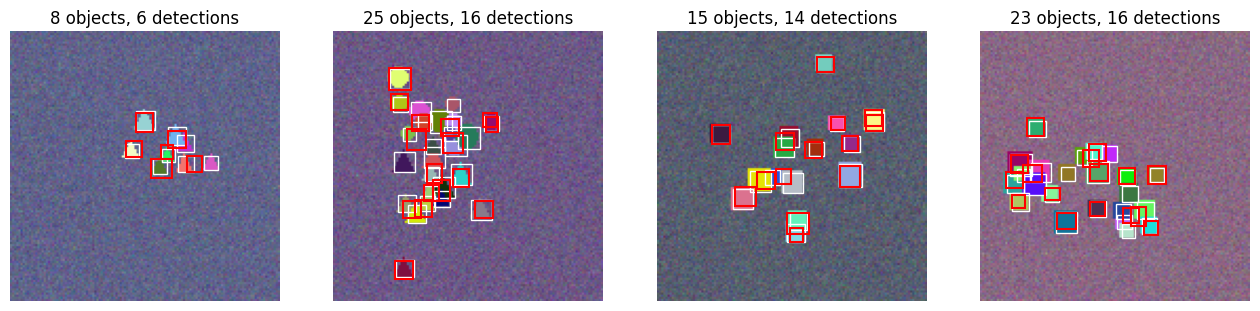

In [6]:
model, losses = train_yolo()
print("mAP:", evaluate(model))
flock_images, flock_objects = test_sets["flock"]
show(flock_images, flock_objects, detect(model, flock_images[:4]))

# Your solution

**Part 1:** why does YOLO lose birds in a flock? **Part 2:** make it find the flock. Results vanish with the runtime, so save what you need to Drive. Good luck!

test scattered   {'objects': 1589, 'green': 1583, 'red': 6, 'limit %': 99.6}
test flock       {'objects': 6199, 'green': 3786, 'red': 2413, 'limit %': 61.1}
train scattered  {'objects': 12095, 'green': 12041, 'red': 54, 'limit %': 99.6}
train flock      {'objects': 44991, 'green': 27889, 'red': 17102, 'limit %': 62.0}
test flock, architecture limit (B boxes per cell): 87.5 %


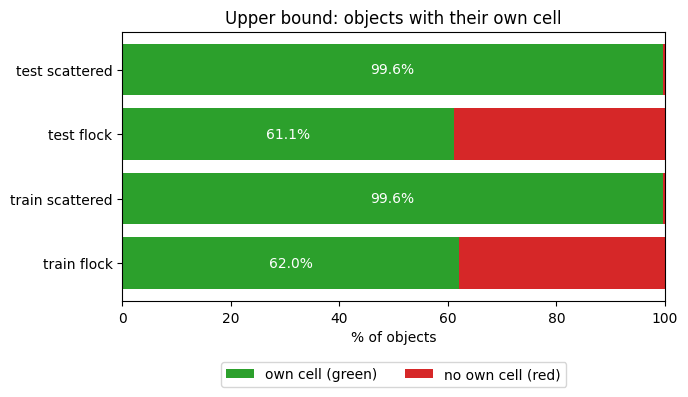

In [7]:
def cell_of(box, S=S):
    """Return (row, col) of the grid cell that holds the centre of box [x0, y0, x1, y1].
    Same formula as in make_targets."""
    x0, y0, x1, y1 = box
    cx, cy = (x0 + x1) / 2 / SIZE * S, (y0 + y1) / 2 / SIZE * S
    return min(int(cy), S - 1), min(int(cx), S - 1)


def cell_status(boxes, S=S):
    """For each object of one image: True = it gets its own cell (green),
    False = an earlier object already took that cell (red). Same rule as make_targets."""
    taken, status = set(), []
    for box in boxes.tolist():
        cell = cell_of(box, S)
        status.append(cell not in taken)
        taken.add(cell)
    return status


def count_limit(objects, S=S):
    """Count green and red objects over a whole set.
    The limit = share of green objects = the most this YOLO is trained to find."""
    green = red = 0
    for boxes, labels in objects:
        status = cell_status(boxes, S)
        green += sum(status)
        red += len(status) - sum(status)
    return {"objects": green + red, "green": green, "red": red,
            "limit %": round(100 * green / (green + red), 1)}


def architecture_limit(objects, S=S, B=B):
    """Most objects the network could output if each cell used all B boxes: min(objects in cell, B) per cell."""
    possible = total = 0
    for boxes, labels in objects:
        cells = [cell_of(box, S) for box in boxes.tolist()]
        possible += sum(min(cells.count(c), B) for c in set(cells))
        total += len(cells)
    return round(100 * possible / total, 1)


def plot_limits(limits):
    """Green vs red share of objects in each set."""
    names = list(limits)
    green = [limits[k]["limit %"] for k in names]
    plt.figure(figsize=(7, 3.5))
    plt.barh(names, green, color="tab:green", label="own cell (green)")
    plt.barh(names, [100 - g for g in green], left=green, color="tab:red", label="no own cell (red)")
    for y, g in enumerate(green):
        plt.text(g / 2, y, f"{g}%", ha="center", va="center", color="white")
    plt.xlim(0, 100); plt.xlabel("% of objects"); plt.gca().invert_yaxis()
    plt.legend(loc="upper center", bbox_to_anchor=(.5, -.2), ncol=2)
    plt.title("Upper bound: objects with their own cell")
    plt.show()


sets = {"test scattered":  test_sets["scattered"][1],
        "test flock":      test_sets["flock"][1],
        "train scattered": train_objects[0::2],
        "train flock":     train_objects[1::2]}
limits = {name: count_limit(objects) for name, objects in sets.items()}
for name, result in limits.items():
    print(f"{name:16s} {result}")
arch_limit = architecture_limit(sets["test flock"])
print("test flock, architecture limit (B boxes per cell):", arch_limit, "%")
plot_limits(limits)

In [8]:
SEEDS = [0, 1, 2]
flock_images, flock_objects = test_sets["flock"]
runs = []
for seed in SEEDS:
    print(f"--- seed {seed} ---")
    model, _ = train_yolo(seed=seed)
    runs.append({"seed": seed, "model": model, "mAP": evaluate(model),
                 "detections": detect(model, flock_images)})
    print("mAP:", runs[-1]["mAP"])

--- seed 0 ---
epoch 1: loss 21.378 (5 s)
epoch 2: loss 6.101 (10 s)
epoch 3: loss 2.991 (15 s)
epoch 4: loss 2.204 (20 s)
epoch 5: loss 1.940 (25 s)
epoch 6: loss 1.854 (30 s)
epoch 7: loss 1.547 (35 s)
epoch 8: loss 1.476 (39 s)
epoch 9: loss 1.368 (44 s)
epoch 10: loss 1.191 (49 s)
epoch 11: loss 1.100 (53 s)
epoch 12: loss 0.940 (58 s)
epoch 13: loss 0.821 (62 s)
epoch 14: loss 0.732 (67 s)
epoch 15: loss 0.680 (71 s)
mAP: {'scattered': 98.7, 'flock': 47.7}
--- seed 1 ---
epoch 1: loss 16.537 (5 s)
epoch 2: loss 5.809 (9 s)
epoch 3: loss 2.901 (14 s)
epoch 4: loss 2.156 (19 s)
epoch 5: loss 1.983 (24 s)
epoch 6: loss 1.841 (28 s)
epoch 7: loss 1.699 (33 s)
epoch 8: loss 1.519 (38 s)
epoch 9: loss 1.436 (43 s)
epoch 10: loss 1.333 (48 s)
epoch 11: loss 1.174 (52 s)
epoch 12: loss 1.029 (57 s)
epoch 13: loss 0.944 (62 s)
epoch 14: loss 0.855 (66 s)
epoch 15: loss 0.807 (71 s)
mAP: {'scattered': 98.2, 'flock': 48.0}
--- seed 2 ---
epoch 1: loss 19.596 (5 s)
epoch 2: loss 6.066 (9 s)
e

seed      mAP scat.   mAP flock   found all found green   found red
0              98.7        47.7        57.8        70.8        37.3
1              98.2        48.0        58.9        70.5        40.7
2              98.4        45.4        57.1        69.1        38.3
mean           98.4        47.0        57.9        70.1        38.8
spread          0.5         2.6         1.8         1.7         3.4


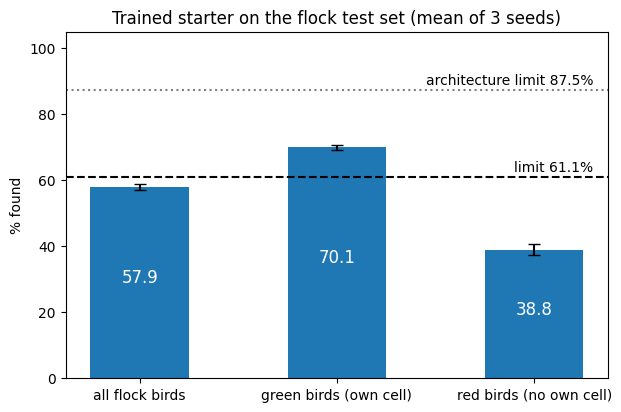

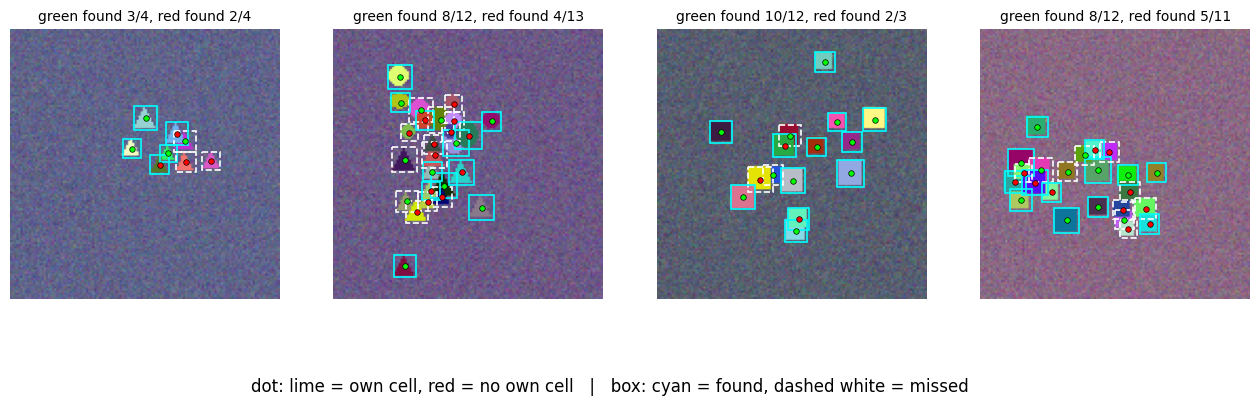

In [9]:
def match_objects(detection, boxes, labels, iou_threshold=.5):
    """For each true object of one image: index of the detection that hit it, or -1 if missed.
    Same matching as average_precision: same class, IoU >= 0.5, highest score first,
    each object can be hit only once."""
    hit_by = torch.full((len(boxes),), -1, dtype=torch.long)
    for c in range(C):
        true_idx = (labels == c).nonzero().flatten()
        det_idx = (detection["labels"] == c).nonzero().flatten()
        if len(true_idx) == 0 or len(det_idx) == 0:
            continue
        det_idx = det_idx[detection["scores"][det_idx].argsort(descending=True)]
        ious = box_iou(detection["boxes"][det_idx], boxes[true_idx])
        for k in range(len(det_idx)):
            best_iou, j = ious[k].max(0)
            if best_iou >= iou_threshold and hit_by[true_idx[j]] < 0:
                hit_by[true_idx[j]] = det_idx[k]
    return hit_by


def recall_by_status(detections, objects):
    """Over a whole set: % of all, green and red objects that were found."""
    found = {"green": 0, "red": 0}
    total = {"green": 0, "red": 0}
    for detection, (boxes, labels) in zip(detections, objects):
        hit = (match_objects(detection, boxes, labels) >= 0).tolist()
        for h, green in zip(hit, cell_status(boxes)):
            key = "green" if green else "red"
            found[key] += h
            total[key] += 1
    return {"all":   round(100 * (found["green"] + found["red"]) / (total["green"] + total["red"]), 1),
            "green": round(100 * found["green"] / total["green"], 1),
            "red":   round(100 * found["red"] / total["red"], 1)}


def print_runs(runs):
    """Table: one row per seed, then the mean and the spread (max - min)."""
    columns = ["mAP scat.", "mAP flock", "found all", "found green", "found red"]
    rows = np.array([[r["mAP"]["scattered"], r["mAP"]["flock"], r["found"]["all"], r["found"]["green"], r["found"]["red"]]
                     for r in runs])
    print("seed   " + "".join(f"{c:>12}" for c in columns))
    for run, row in zip(runs, rows):
        print(f"{run['seed']:<7}" + "".join(f"{v:>12.1f}" for v in row))
    print("mean   " + "".join(f"{v:>12.1f}" for v in rows.mean(0)))
    print("spread " + "".join(f"{v:>12.1f}" for v in rows.max(0) - rows.min(0)))


def plot_found(runs, limit, arch_limit):
    """Bars = mean over seeds (error bar = min..max) of the % of all / green / red birds found.
    Dashed line = the limit from cell 1, dotted line = the architecture limit."""
    groups, x = ["all", "green", "red"], np.arange(3)
    values = np.array([[run["found"][g] for g in groups] for run in runs])   # (seeds, 3)
    mean = values.mean(0)
    plt.figure(figsize=(7, 4.5))
    plt.bar(x, mean, width=.5, yerr=[mean - values.min(0), values.max(0) - mean], capsize=4)
    for xi, m in zip(x, mean):
        plt.text(xi, m / 2, f"{m:.1f}", ha="center", color="white", fontsize=12)
    plt.axhline(limit, ls="--", color="black"); plt.text(2.3, limit + 1.5, f"limit {limit}%", ha="right")
    plt.axhline(arch_limit, ls=":", color="gray"); plt.text(2.3, arch_limit + 1.5, f"architecture limit {arch_limit}%", ha="right")
    plt.xticks(x, ["all flock birds", "green birds (own cell)", "red birds (no own cell)"])
    plt.ylabel("% found"); plt.ylim(0, 105)
    plt.title(f"Trained starter on the flock test set (mean of {len(runs)} seeds)")
    plt.show()


def show_found(images, objects, detections, n=4):
    """Draw n images. Dot = cell status (lime = own cell, red = no own cell).
    Box = result (solid cyan = found, dashed white = missed)."""
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4.6))
    for i, ax in enumerate(axes):
        ax.imshow(images[i].permute(1, 2, 0).cpu()); ax.axis("off")
        boxes, labels = objects[i]
        hit = (match_objects(detections[i], boxes, labels) >= 0).tolist()
        status = cell_status(boxes)
        for (x0, y0, x1, y1), h, green in zip(boxes.tolist(), hit, status):
            ax.add_patch(plt.Rectangle((x0 - 1, y0 - 1), x1 - x0 + 2, y1 - y0 + 2, fill=False,
                                       color="cyan" if h else "white", ls="-" if h else "--", lw=1.2))
            ax.plot((x0 + x1) / 2, (y0 + y1) / 2, "o", ms=4, mec="black", mew=.5, color="lime" if green else "red")
        g = [h for h, s in zip(hit, status) if s]
        r = [h for h, s in zip(hit, status) if not s]
        ax.set_title(f"green found {sum(g)}/{len(g)}, red found {sum(r)}/{len(r)}", fontsize=10)
    fig.suptitle("dot: lime = own cell, red = no own cell   |   box: cyan = found, dashed white = missed", y=.03)
    plt.show()


for run in runs:
    run["found"] = recall_by_status(run["detections"], flock_objects)
print_runs(runs)
plot_found(runs, limits["test flock"]["limit %"], arch_limit)
show_found(flock_images, flock_objects, runs[0]["detections"])

seed 0:
   found per cell (1/2/3/4+ birds): [0.91 1.05 0.94 0.81]
   cells with 2+ birds: {'only green': 22.1, 'swap (red, not green)': 29.2, 'green + red': 22.7, 'nothing': 26.0}
   red found by: {'own cell': 91.6, 'other cell': 8.4}
   cells whose own boxes found 2+ birds: 21.4%
seed 1:
   found per cell (1/2/3/4+ birds): [0.89 1.12 0.98 0.89]
   cells with 2+ birds: {'only green': 20.2, 'swap (red, not green)': 30.4, 'green + red': 26.0, 'nothing': 23.5}
   red found by: {'own cell': 92.6, 'other cell': 7.4}
   cells whose own boxes found 2+ birds: 25.1%
seed 2:
   found per cell (1/2/3/4+ birds): [0.88 1.08 0.9  0.8 ]
   cells with 2+ birds: {'only green': 21.4, 'swap (red, not green)': 30.9, 'green + red': 22.7, 'nothing': 25.0}
   red found by: {'own cell': 91.7, 'other cell': 8.3}
   cells whose own boxes found 2+ birds: 21.1%


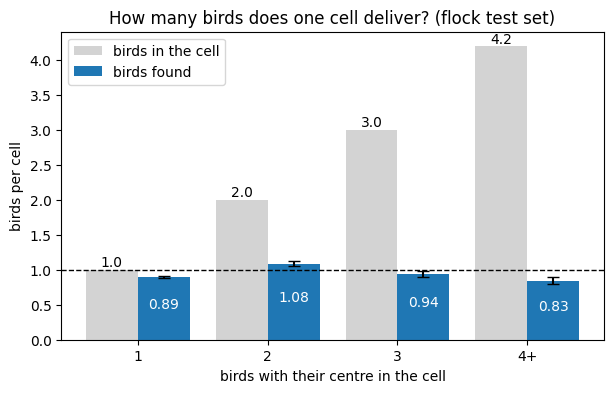

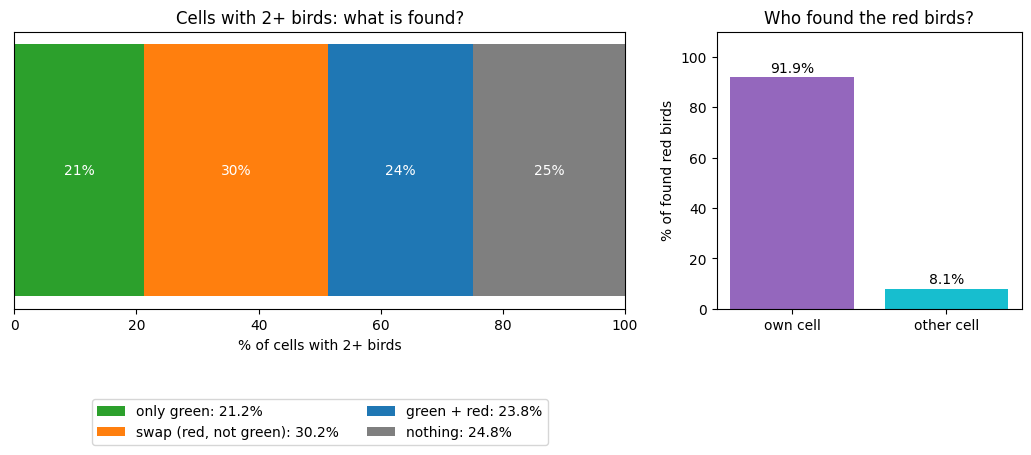

In [10]:
def bird_records(detections, objects):
    """One record per bird: its cell, green/red, found or not, and which cell's box found it.
    A predicted box always has its centre in its own cell (sigmoid on x, y), so cell_of(box) = its cell."""
    records = []
    for n, (detection, (boxes, labels)) in enumerate(zip(detections, objects)):
        hit_by = match_objects(detection, boxes, labels).tolist()
        for box, green, d in zip(boxes.tolist(), cell_status(boxes), hit_by):
            records.append({"image": n, "cell": cell_of(box), "green": green, "found": d >= 0,
                            "found_by": cell_of(detection["boxes"][d].tolist()) if d >= 0 else None})
    return records


def cell_groups(records):
    """Group the birds by (image, cell): one list per occupied cell."""
    groups = {}
    for r in records:
        groups.setdefault((r["image"], r["cell"]), []).append(r)
    return list(groups.values())


def found_per_cell(records):
    """For cells holding 1, 2, 3, 4+ birds: mean number of birds in them and mean number found."""
    birds, found, cells = np.zeros(4), np.zeros(4), np.zeros(4)
    for group in cell_groups(records):
        k = min(len(group), 4) - 1
        birds[k] += len(group); found[k] += sum(r["found"] for r in group); cells[k] += 1
    return birds / cells, found / cells


def crowded_outcomes(records):
    """Cells with 2+ birds: % where only the green bird was found, a red one instead of the green (swap),
    both green and red found, or nothing found."""
    out = {"only green": 0, "swap (red, not green)": 0, "green + red": 0, "nothing": 0}
    for group in cell_groups(records):
        if len(group) < 2:
            continue
        green_found = [r for r in group if r["green"]][0]["found"]
        red_found = any(r["found"] for r in group if not r["green"])
        if green_found and red_found: out["green + red"] += 1
        elif green_found:             out["only green"] += 1
        elif red_found:               out["swap (red, not green)"] += 1
        else:                         out["nothing"] += 1
    total = sum(out.values())
    return {key: 100 * value / total for key, value in out.items()}


def who_found_red(records):
    """Found red birds: % hit by a box of their own cell vs a box of another (neighbouring) cell."""
    found_red = [r for r in records if not r["green"] and r["found"]]
    own = sum(r["found_by"] == r["cell"] for r in found_red)
    return {"own cell": 100 * own / len(found_red), "other cell": 100 * (len(found_red) - own) / len(found_red)}


def two_boxes_used(records):
    """Cells with 2+ birds: % where the cell's own boxes found 2 or more different birds
    (the case where the 2 boxes 'rescue' a red bird)."""
    used = total = 0
    for group in cell_groups(records):
        if len(group) >= 2:
            total += 1
            used += sum(r["found_by"] == r["cell"] for r in group) >= 2
    return 100 * used / total


def plot_per_cell(analysis):
    """Bars: birds in a cell vs birds found in it (mean over seeds), for cells with 1, 2, 3, 4+ birds."""
    birds = np.mean([a["per cell"][0] for a in analysis], 0)
    found = np.array([a["per cell"][1] for a in analysis])
    x = np.arange(4)
    plt.figure(figsize=(7, 4))
    plt.bar(x - .2, birds, width=.4, color="lightgray", label="birds in the cell")
    plt.bar(x + .2, found.mean(0), width=.4, color="tab:blue", label="birds found",
            yerr=[found.mean(0) - found.min(0), found.max(0) - found.mean(0)], capsize=4)
    for xi, b, f in zip(x, birds, found.mean(0)):
        plt.text(xi - .2, b + .05, f"{b:.1f}", ha="center"); plt.text(xi + .2, f / 2, f"{f:.2f}", ha="center", color="white")
    plt.axhline(1, ls="--", color="black", lw=1)
    plt.xticks(x, ["1", "2", "3", "4+"]); plt.xlabel("birds with their centre in the cell")
    plt.ylabel("birds per cell"); plt.legend(loc="upper left")
    plt.title("How many birds does one cell deliver? (flock test set)")
    plt.show()


def plot_crowded(analysis):
    """Left: what happens in cells with 2+ birds. Right: which cell found the red birds that were found."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2, 1]})
    outcomes = {k: np.mean([a["crowded"][k] for a in analysis]) for k in analysis[0]["crowded"]}
    left = 0
    for (name, value), colour in zip(outcomes.items(), ["tab:green", "tab:orange", "tab:blue", "tab:gray"]):
        ax1.barh([0], [value], left=left, color=colour, label=f"{name}: {value:.1f}%")
        ax1.text(left + value / 2, 0, f"{value:.0f}%", ha="center", va="center", color="white")
        left += value
    ax1.set_xlim(0, 100); ax1.set_yticks([]); ax1.set_xlabel("% of cells with 2+ birds")
    ax1.legend(loc="upper center", bbox_to_anchor=(.5, -.3), ncol=2); ax1.set_title("Cells with 2+ birds: what is found?")
    who = {k: np.mean([a["red found by"][k] for a in analysis]) for k in analysis[0]["red found by"]}
    ax2.bar(list(who), list(who.values()), color=["tab:purple", "tab:cyan"])
    for i, v in enumerate(who.values()):
        ax2.text(i, v + 2, f"{v:.1f}%", ha="center")
    ax2.set_ylim(0, 110); ax2.set_ylabel("% of found red birds"); ax2.set_title("Who found the red birds?")
    plt.show()


analysis = []
for run in runs:
    records = bird_records(run["detections"], flock_objects)
    analysis.append({"seed": run["seed"], "per cell": found_per_cell(records), "crowded": crowded_outcomes(records),
                     "red found by": who_found_red(records), "two boxes": two_boxes_used(records)})
for a in analysis:
    print(f"seed {a['seed']}:")
    print("   found per cell (1/2/3/4+ birds):", np.round(a["per cell"][1], 2))
    print("   cells with 2+ birds:", {k: round(v, 1) for k, v in a["crowded"].items()})
    print("   red found by:", {k: round(v, 1) for k, v in a["red found by"].items()})
    print(f"   cells whose own boxes found 2+ birds: {a['two boxes']:.1f}%")
plot_per_cell(analysis)
plot_crowded(analysis)

In [11]:
# ============ Part 2 (MVP): a finer grid, 16x16 instead of 8x8 ============
# The only change: the last downsampling convolution keeps the size (stride 1 instead of 2),
# so the network ends on a 16x16 grid (cells of 8x8 pixels) instead of 8x8 (cells of 16x16 pixels).
# Everything else (make_targets, yolo_loss, detect, train_yolo, evaluate) is the starter's code, unchanged:
# it reads S and row/col, so it follows the new grid automatically.
S = 16
row, col = torch.meshgrid(torch.arange(S, device=device), torch.arange(S, device=device), indexing="ij")

class TinyYOLO(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(*conv(3, 32, 1), *conv(32, 64, 2), *conv(64, 64, 1), *conv(64, 128, 2), *conv(128, 128, 1),
                                 *conv(128, 256, 2), *conv(256, 256, 1), *conv(256, 256, 1),   # <- was stride 2
                                 nn.Conv2d(256, B * 5 + C, 1))

    def forward(self, images):
        return self.net(images.float() / 255 - .5).permute(0, 2, 3, 1)

train_targets = make_targets(train_objects)          # the targets on the 16x16 grid
print("training targets:", tuple(train_targets.shape))
flock_images, flock_objects = test_sets["flock"]
print("limit on the flock test set:", count_limit(flock_objects, S=16)["limit %"], "% (8x8 grid: 61.1 %)")

mvp_runs = []
for seed in [0, 1, 2]:
    print(f"--- seed {seed} ---")
    model, _ = train_yolo(seed=seed)
    mvp_runs.append({"seed": seed, "mAP": evaluate(model), "found": recall_by_status(detect(model, flock_images), flock_objects)})
    print("mAP:", mvp_runs[-1]["mAP"])
print_runs(mvp_runs)

training targets: (6000, 16, 16, 8)
limit on the flock test set: 92.8 % (8x8 grid: 61.1 %)
--- seed 0 ---
epoch 1: loss 54.415 (5 s)
epoch 2: loss 14.444 (10 s)
epoch 3: loss 6.318 (15 s)
epoch 4: loss 3.728 (20 s)
epoch 5: loss 3.063 (25 s)
epoch 6: loss 2.837 (30 s)
epoch 7: loss 2.677 (36 s)
epoch 8: loss 2.563 (41 s)
epoch 9: loss 2.423 (46 s)
epoch 10: loss 2.321 (51 s)
epoch 11: loss 2.219 (56 s)
epoch 12: loss 2.228 (61 s)
epoch 13: loss 2.034 (66 s)
epoch 14: loss 2.009 (71 s)
epoch 15: loss 1.987 (76 s)
mAP: {'scattered': 99.5, 'flock': 87.1}
--- seed 1 ---
epoch 1: loss 38.407 (5 s)
epoch 2: loss 11.104 (10 s)
epoch 3: loss 5.745 (15 s)
epoch 4: loss 3.855 (20 s)
epoch 5: loss 2.840 (25 s)
epoch 6: loss 2.654 (30 s)
epoch 7: loss 2.608 (35 s)
epoch 8: loss 2.609 (40 s)
epoch 9: loss 2.491 (45 s)
epoch 10: loss 2.255 (51 s)
epoch 11: loss 2.224 (56 s)
epoch 12: loss 2.117 (61 s)
epoch 13: loss 2.064 (66 s)
epoch 14: loss 1.979 (71 s)
epoch 15: loss 1.952 (75 s)
mAP: {'scattere